In [1]:
pip install pdfplumber pandas openpyxl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 64.3 MB/s eta 0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0


In [2]:
import re
import pdfplumber
import pandas as pd

# ============================================================
# 1. PDF FILE
# ============================================================

PDF_PATH = "/content/SPBU-DM third Year SEMESTER 6_260611_175642.pdf"

# ============================================================
# 2. COLUMN NAMES
# ============================================================

columns = [
    "Teeth Whitening",
    "General Physiotherapy",
    "Head and Neck Anatomic Pathology",
    "Diagnosis Radiology",
    "Surgical Diseases",
    "Military and Extrem Medicine",
    "Prosthetic Dentistry",
    "Pathophysiology",
    "Preventive Care",
    "Pediatric Dentistry",
    "Therapeutics Dentistry",
    "Dental Surgery"
]

# ============================================================
# 3. READ PDF
# ============================================================

with pdfplumber.open(PDF_PATH) as pdf:

    all_text = ""

    for page in pdf.pages:
        text = page.extract_text()

        if text:
            all_text += text + "\n"


# ============================================================
# 4. EXTRACT STUDENT ROWS
# ============================================================

lines = all_text.splitlines()

students = []

# Grade pattern:
# A, B, C, D, E, F
grade_pattern = r"\b([ABCDEF])\s+(?:Passed|Good|Excellent|Satisfactory|Failed)\b"

for line in lines:

    # Find Student ID
    id_match = re.search(r"\b(\d{6})\s*$", line)

    if not id_match:
        continue

    student_id = id_match.group(1)

    # Extract all grades from the row
    grades = re.findall(grade_pattern, line)

    # We expect 12 grades
    if len(grades) == 12:

        student = {
            "Student ID": student_id
        }

        for column, grade in zip(columns, grades):
            student[column] = grade

        students.append(student)

    else:
        print(
            f"WARNING: Student {student_id} has "
            f"{len(grades)} grades instead of 12"
        )


# ============================================================
# 5. CREATE DATAFRAME
# ============================================================

df = pd.DataFrame(students)

# Make sure columns are in the correct order
df = df[["Student ID"] + columns]


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 100)
print("STUDENT RESULTS")
print("=" * 100)

print(df.to_string(index=False))


# ============================================================
# 7. SAVE AS CSV
# ============================================================

df.to_csv(
    "students_results.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. SAVE AS EXCEL
# ============================================================

df.to_excel(
    "students_results.xlsx",
    index=False
)


# ============================================================
# 9. SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("DONE")
print("=" * 100)

print(f"Students extracted : {len(df)}")
print(f"Columns            : {len(df.columns)}")

print("\nFiles created:")
print("1. students_results.xlsx")
print("2. students_results.csv")

print("\nFirst 5 students:")
print(df.head())


STUDENT RESULTS
Student ID Teeth Whitening General Physiotherapy Head and Neck Anatomic Pathology Diagnosis Radiology Surgical Diseases Military and Extrem Medicine Prosthetic Dentistry Pathophysiology Preventive Care Pediatric Dentistry Therapeutics Dentistry Dental Surgery
    124758               F                     E                                E                   F                 F                            F                    E               C               F                   F                      C              E
    124760               F                     C                                E                   F                 D                            E                    F               C               C                   F                      B              D
    124761               D                     B                                C                   C                 C                            D                    D               B               B  

In [3]:
import pdfplumber
import pandas as pd
import re

# ============================================================
# PDF FILE
# ============================================================

PDF_PATH = "/content/SPBU-DM third Year SEMESTER 6_260611_175642.pdf"


# ============================================================
# SUBJECTS - EXACT ORDER IN THE PDF
# ============================================================

subjects = [
    "Teeth Whitening",
    "Preventive Care",
    "Pediatric Dentistry",
    "Therapeutics Dentistry",
    "Prosthetic Dentistry",
    "Dental Surgery",
    "Pathophysiology",
    "General Physiotherapy",
    "Head and Neck Anatomic Pathology",
    "Diagnosis Radiology",
    "Military and Extrem Medicine",
    "Surgical Diseases"
]


# ============================================================
# EXTRACT TABLE FROM PDF
# ============================================================

with pdfplumber.open(PDF_PATH) as pdf:

    page = pdf.pages[0]

    tables = page.extract_tables()

    if not tables:
        raise ValueError("No table found in the PDF.")

    table = tables[0]


# ============================================================
# CHECK TABLE
# ============================================================

print("=" * 100)
print("TABLE INFORMATION")
print("=" * 100)

print(f"Rows    : {len(table)}")
print(f"Columns : {len(table[0])}")

print()


# ============================================================
# STUDENT DATA
# ============================================================

students = []


# ============================================================
# PROCESS EACH ROW
# ============================================================

for row in table:

    # Make sure row has enough columns
    if len(row) < 25:
        continue

    # Student ID is the last column
    student_id = row[24]

    if student_id is None:
        continue

    student_id = str(student_id).strip()

    # Student IDs are 6 digits
    if not re.fullmatch(r"\d{6}", student_id):
        continue


    # ========================================================
    # CREATE STUDENT RECORD
    # ========================================================

    student = {
        "Student ID": student_id
    }


    # ========================================================
    # EACH SUBJECT OCCUPIES 2 COLUMNS
    #
    # Example:
    #
    # column 0 = Letter
    # column 1 = Result
    #
    # column 2 = Letter
    # column 3 = Result
    #
    # etc.
    # ========================================================

    for i, subject in enumerate(subjects):

        letter_column = i * 2
        result_column = i * 2 + 1

        letter = row[letter_column]
        result = row[result_column]

        if letter is None:
            letter = ""

        if result is None:
            result = ""

        letter = str(letter).strip()
        result = str(result).strip()

        student[f"{subject} - Grade"] = letter
        student[f"{subject} - Result"] = result


    students.append(student)


# ============================================================
# CREATE DATAFRAME
# ============================================================

df = pd.DataFrame(students)


# ============================================================
# SORT BY STUDENT ID
# ============================================================

df["Student ID"] = df["Student ID"].astype(str)

df = df.sort_values("Student ID")


# ============================================================
# DISPLAY
# ============================================================

print("=" * 100)
print("EXTRACTED STUDENTS")
print("=" * 100)

print(f"Number of students: {len(df)}")
print()


# Display first 10 students
print(df.head(10).to_string(index=False))


# ============================================================
# SAVE EXCEL
# ============================================================

excel_file = "students_results.xlsx"

df.to_excel(
    excel_file,
    index=False
)


# ============================================================
# SAVE CSV
# ============================================================

csv_file = "students_results.csv"

df.to_csv(
    csv_file,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# CREATE A CLEAN LONG FORMAT
#
# This is useful if you want:
#
# Student ID | Subject | Grade | Result
#
# ============================================================

long_data = []

for _, row in df.iterrows():

    student_id = row["Student ID"]

    for subject in subjects:

        grade = row[f"{subject} - Grade"]
        result = row[f"{subject} - Result"]

        long_data.append({
            "Student ID": student_id,
            "Subject": subject,
            "Grade": grade,
            "Result": result
        })


long_df = pd.DataFrame(long_data)


# ============================================================
# SAVE LONG FORMAT
# ============================================================

long_excel_file = "students_results_by_subject.xlsx"

long_df.to_excel(
    long_excel_file,
    index=False
)


# ============================================================
# FINAL INFORMATION
# ============================================================

print()
print("=" * 100)
print("DONE")
print("=" * 100)

print(f"Students extracted : {len(df)}")
print(f"Subjects           : {len(subjects)}")

print()
print("Files created:")

print(f"1. {excel_file}")
print(f"2. {csv_file}")
print(f"3. {long_excel_file}")


# ============================================================
# VERIFY FIRST STUDENT
# ============================================================

print()
print("=" * 100)
print("FIRST STUDENT VERIFICATION")
print("=" * 100)

first_student = df.iloc[0]

print(f"\nStudent ID: {first_student['Student ID']}\n")

for subject in subjects:

    grade = first_student[f"{subject} - Grade"]
    result = first_student[f"{subject} - Result"]

    print(f"{subject:<40} {grade:<3} {result}")

TABLE INFORMATION
Rows    : 64
Columns : 25

EXTRACTED STUDENTS
Number of students: 59

Student ID Teeth Whitening - Grade Teeth Whitening - Result Preventive Care - Grade Preventive Care - Result Pediatric Dentistry - Grade Pediatric Dentistry - Result Therapeutics Dentistry - Grade Therapeutics Dentistry - Result Prosthetic Dentistry - Grade Prosthetic Dentistry - Result Dental Surgery - Grade Dental Surgery - Result Pathophysiology - Grade Pathophysiology - Result General Physiotherapy - Grade General Physiotherapy - Result Head and Neck Anatomic Pathology - Grade Head and Neck Anatomic Pathology - Result Diagnosis Radiology - Grade Diagnosis Radiology - Result Military and Extrem Medicine - Grade Military and Extrem Medicine - Result Surgical Diseases - Grade Surgical Diseases - Result
    124758                       F                   Failed                       E             Satisfactory                           E                       Passed                              F   

In [4]:
# 2. SUBJECT CREDITS

credits = {

    # 2 Credit
    "Teeth Whitening": 2,
    "General Physiotherapy": 2,
    "Head and Neck Anatomic Pathology": 2,
    "Therapeutics Dentistry": 2,
    "Pathophysiology": 2,

    # 3 Credit
    "Preventive Care": 3,
    "Pediatric Dentistry": 3,
    "Prosthetic Dentistry": 3,
    "Dental Surgery": 3,

    # 1 Credit
    "Military and Extrem Medicine": 1,
    "Surgical Diseases": 1
}

In [5]:
# 3. GRADE POINTS

grade_points = {
    "A": 3.666,
    "B": 3.000,
    "C": 2.333,
    "D": 2.000,
    "E": 1.000,
    "F": 0.000
}

# 4. SUBJECTS

subjects = list(credits.keys())


In [6]:
# 5. CHECK CREDITS

total_credits = sum(credits.values())

print("Total Credits:", total_credits)

assert total_credits == 24, (
    f"Expected 24 credits, but got {total_credits}"
)

Total Credits: 24


In [7]:
# 6. CALCULATE WEIGHTED GPA FOR EACH STUDENT

results = []


for _, student in df.iterrows():

    student_id = student["Student ID"]

    total_weighted_points = 0
    total_credits_taken = 0

    student_result = {
        "Student ID": student_id
    }

    # Calculate each subject

    for subject in subjects:

        grade_column = f"{subject} - Grade"

        grade = str(student[grade_column]).strip().upper()

        credit = credits[subject]

        point = grade_points[grade]

        weighted_point = point * credit

        total_weighted_points += weighted_point
        total_credits_taken += credit

        # Save useful information
        student_result[f"{subject} - Credit"] = credit
        student_result[f"{subject} - Grade Point"] = point
        student_result[f"{subject} - Weighted Points"] = weighted_point

    # Overall GPA
    overall_gpa = (
        total_weighted_points / total_credits_taken
    )

    student_result["Total Credits"] = total_credits_taken
    student_result["Total Weighted Points"] = total_weighted_points
    student_result["Overall GPA"] = overall_gpa

    results.append(student_result)


In [8]:
# 7. CREATE GPA DATAFRAME

gpa_df = pd.DataFrame(results)


# 8. ROUND GPA

gpa_df["Overall GPA"] = gpa_df["Overall GPA"].round(3)

gpa_df["Total Weighted Points"] = (
    gpa_df["Total Weighted Points"].round(3)
)

In [9]:
# 9. CONVERT GPA TO OVERALL LETTER

def get_overall_grade(gpa):

    if gpa >= 3.666:
        return "A"

    elif gpa >= 3.000:
        return "B"

    elif gpa >= 2.333:
        return "C"

    elif gpa >= 2.000:
        return "D"

    elif gpa >= 1.000:
        return "E"

    else:
        return "F"


gpa_df["Overall Grade"] = (
    gpa_df["Overall GPA"]
    .apply(get_overall_grade)
)

In [10]:
# 10. MERGE WITH ORIGINAL DATA

final_df = df.merge(
    gpa_df[
        [
            "Student ID",
            "Total Credits",
            "Total Weighted Points",
            "Overall GPA",
            "Overall Grade"
        ]
    ],
    on="Student ID",
    how="left"
)


In [11]:
# 11. DISPLAY MAIN RESULT

print()
print("=" * 100)
print("OVERALL RESULTS")
print("=" * 100)

print(
    final_df[
        [
            "Student ID",
            "Total Credits",
            "Total Weighted Points",
            "Overall GPA",
            "Overall Grade"
        ]
    ].to_string(index=False)
)



OVERALL RESULTS
Student ID  Total Credits  Total Weighted Points  Overall GPA Overall Grade
    124758             24                 15.999        0.667             F
    124760             24                 33.331        1.389             E
    124761             24                 58.330        2.430             C
    124762             24                 61.662        2.569             C
    124764             24                 51.996        2.166             D
    124766             24                 52.328        2.180             D
    124767             24                 65.328        2.722             C
    124771             24                 34.999        1.458             E
    124772             24                 34.666        1.444             E
    124773             24                 72.660        3.028             B
    124776             24                 59.331        2.472             C
    124777             24                 61.329        2.555          

In [12]:
# 12. COUNT STUDENTS BY OVERALL GRADE

grade_distribution = (
    final_df["Overall Grade"]
    .value_counts()
    .reindex(
        ["A", "B", "C", "D", "E", "F"],
        fill_value=0
    )
)


print()
print("=" * 100)
print("OVERALL GRADE DISTRIBUTION")
print("=" * 100)

print(grade_distribution)



OVERALL GRADE DISTRIBUTION
Overall Grade
A     0
B     5
C    24
D    14
E    11
F     5
Name: count, dtype: int64


In [13]:
# 13. PERCENTAGE OF EACH GRADE

grade_distribution_percentage = (
    grade_distribution / len(final_df) * 100
).round(2)


distribution_df = pd.DataFrame({
    "Students": grade_distribution,
    "Percentage": grade_distribution_percentage
})


print()
print("=" * 100)
print("GRADE DISTRIBUTION WITH PERCENTAGES")
print("=" * 100)

print(distribution_df)



GRADE DISTRIBUTION WITH PERCENTAGES
               Students  Percentage
Overall Grade                      
A                     0        0.00
B                     5        8.47
C                    24       40.68
D                    14       23.73
E                    11       18.64
F                     5        8.47


In [14]:
# 14. SORT STUDENTS BY GPA

ranking_df = (
    final_df[
        [
            "Student ID",
            "Overall GPA",
            "Overall Grade"
        ]
    ]
    .sort_values(
        by="Overall GPA",
        ascending=False
    )
    .reset_index(drop=True)
)


In [15]:
# Add Rank
ranking_df.insert(
    0,
    "Rank",
    range(1, len(ranking_df) + 1)
)


print()
print("=" * 100)
print("STUDENT RANKING")
print("=" * 100)

print(ranking_df.to_string(index=False))


STUDENT RANKING
 Rank Student ID  Overall GPA Overall Grade
    1     124779        3.278             B
    2     124816        3.194             B
    3     124838        3.111             B
    4     124773        3.028             B
    5     124836        3.028             B
    6     124792        2.944             C
    7     124823        2.916             C
    8     124800        2.889             C
    9     124833        2.889             C
   10     124795        2.805             C
   11     125103        2.778             C
   12     124825        2.750             C
   13     124780        2.750             C
   14     124767        2.722             C
   15     124794        2.722             C
   16     124802        2.639             C
   17     124803        2.583             C
   18     124762        2.569             C
   19     125104        2.555             C
   20     124777        2.555             C
   21     124797        2.555             C
   22     12482

In [16]:
# 15. SAVE RESULTS

final_df.to_csv(
    "/content/students_results_with_gpa.csv",
    index=False,
    encoding="utf-8-sig"
)

final_df.to_excel(
    "/content/students_results_with_gpa.xlsx",
    index=False
)

ranking_df.to_csv(
    "/content/student_ranking.csv",
    index=False,
    encoding="utf-8-sig"
)

ranking_df.to_excel(
    "/content/student_ranking.xlsx",
    index=False
)

In [17]:
# 16. FINAL SUMMARY

print()
print("=" * 100)
print("FINAL SUMMARY")
print("=" * 100)

print(f"Number of students : {len(final_df)}")
print(f"Total credits      : {total_credits}")

print()

for grade in ["A", "B", "C", "D", "E", "F"]:

    count = grade_distribution[grade]
    percentage = grade_distribution_percentage[grade]

    print(
        f"{grade}: {count} students ({percentage}%)"
    )

print()
print("Files saved:")
print("/content/students_results_with_gpa.csv")
print("/content/students_results_with_gpa.xlsx")
print("/content/student_ranking.csv")
print("/content/student_ranking.xlsx")


FINAL SUMMARY
Number of students : 59
Total credits      : 24

A: 0 students (0.0%)
B: 5 students (8.47%)
C: 24 students (40.68%)
D: 14 students (23.73%)
E: 11 students (18.64%)
F: 5 students (8.47%)

Files saved:
/content/students_results_with_gpa.csv
/content/students_results_with_gpa.xlsx
/content/student_ranking.csv
/content/student_ranking.xlsx


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# OVERALL STATISTICS

print("=" * 70)
print("OVERALL STATISTICS")
print("=" * 70)

print(f"Number of Students : {len(final_df)}")
print(f"Total Credits      : {final_df['Total Credits'].iloc[0]}")

print(f"Average GPA        : {final_df['Overall GPA'].mean():.3f}")
print(f"Median GPA         : {final_df['Overall GPA'].median():.3f}")
print(f"Minimum GPA        : {final_df['Overall GPA'].min():.3f}")
print(f"Maximum GPA        : {final_df['Overall GPA'].max():.3f}")
print(f"Std GPA            : {final_df['Overall GPA'].std():.3f}")

OVERALL STATISTICS
Number of Students : 59
Total Credits      : 24
Average GPA        : 2.173
Median GPA         : 2.305
Minimum GPA        : 0.000
Maximum GPA        : 3.278
Std GPA            : 0.727


In [19]:
# OVERALL GRADE DISTRIBUTION

grade_order = ["A", "B", "C", "D", "E", "F"]

grade_counts = (
    final_df["Overall Grade"]
    .value_counts()
    .reindex(grade_order, fill_value=0)
)

grade_percentages = (
    grade_counts / len(final_df) * 100
).round(2)

grade_summary = pd.DataFrame({
    "Students": grade_counts,
    "Percentage": grade_percentages
})

print(grade_summary)

               Students  Percentage
Overall Grade                      
A                     0        0.00
B                     5        8.47
C                    24       40.68
D                    14       23.73
E                    11       18.64
F                     5        8.47


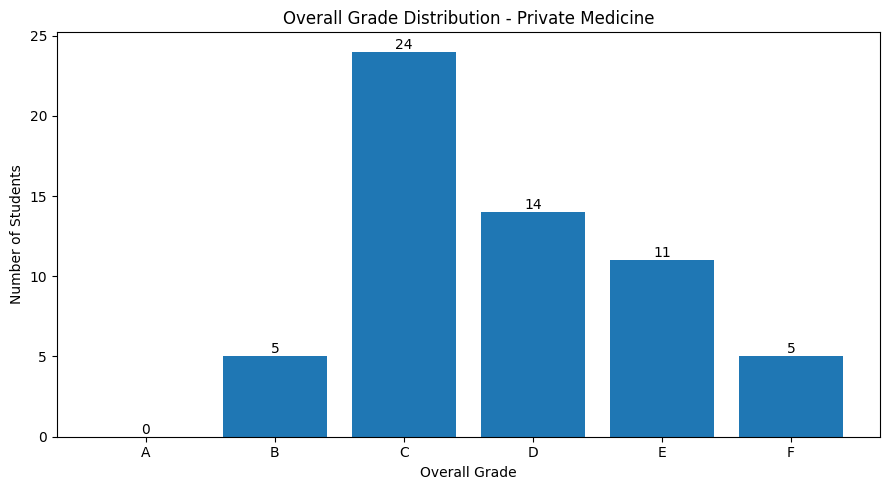

In [20]:
# BAR CHART - OVERALL GRADES

plt.figure(figsize=(9, 5))

bars = plt.bar(
    grade_summary.index,
    grade_summary["Students"]
)

plt.title("Overall Grade Distribution - Private Medicine")
plt.xlabel("Overall Grade")
plt.ylabel("Number of Students")

for bar, value in zip(bars, grade_summary["Students"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

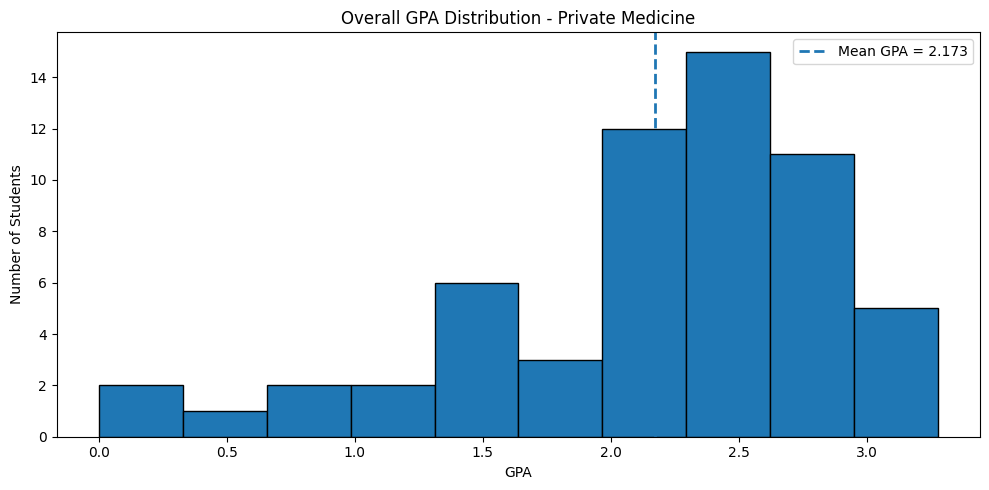

In [21]:
# GPA DISTRIBUTION

plt.figure(figsize=(10, 5))

plt.hist(
    final_df["Overall GPA"],
    bins=10,
    edgecolor="black"
)

plt.axvline(
    final_df["Overall GPA"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean GPA = {final_df['Overall GPA'].mean():.3f}"
)

plt.title("Overall GPA Distribution - Private Medicine")
plt.xlabel("GPA")
plt.ylabel("Number of Students")

plt.legend()

plt.tight_layout()
plt.show()

In [22]:
# SUBJECT ANALYSIS

subject_analysis = []

for subject in subjects:

    grade_col = f"{subject} - Grade"

    grades = final_df[grade_col].astype(str).str.strip().str.upper()

    total_students = len(grades)

    counts = (
        grades
        .value_counts()
        .reindex(grade_order, fill_value=0)
    )

    # Average grade point
    avg_grade_point = grades.map(grade_points).mean()

    # Pass / Fail
    pass_count = (grades != "F").sum()
    fail_count = (grades == "F").sum()

    pass_rate = pass_count / total_students * 100
    fail_rate = fail_count / total_students * 100

    subject_analysis.append({
        "Subject": subject,
        "Credits": credits[subject],
        "Average Grade Point": avg_grade_point,

        "A Count": counts["A"],
        "A %": counts["A"] / total_students * 100,

        "B Count": counts["B"],
        "B %": counts["B"] / total_students * 100,

        "C Count": counts["C"],
        "C %": counts["C"] / total_students * 100,

        "D Count": counts["D"],
        "D %": counts["D"] / total_students * 100,

        "E Count": counts["E"],
        "E %": counts["E"] / total_students * 100,

        "F Count": counts["F"],
        "F %": counts["F"] / total_students * 100,

        "Pass Rate %": pass_rate,
        "Fail Rate %": fail_rate
    })


subject_analysis_df = pd.DataFrame(subject_analysis)

subject_analysis_df[
    [
        "Subject",
        "Credits",
        "Average Grade Point",
        "Pass Rate %",
        "Fail Rate %",
        "A %",
        "F %"
    ]
].sort_values(
    "Average Grade Point",
    ascending=False
)

,Subject,Credits,Average Grade Point,Pass Rate %,Fail Rate %,A %,F %
1,General Physiotherapy,2,2.722932,98.305085,1.694915,15.254237,1.694915
9,Military and Extrem Medicine,1,2.530881,98.305085,1.694915,5.084746,1.694915
2,Head and Neck Anatomic Pathology,2,2.423576,91.525424,8.474576,10.169492,8.474576
5,Preventive Care,3,2.406593,96.610169,3.389831,6.779661,3.389831
0,Teeth Whitening,2,2.327525,91.525424,8.474576,15.254237,8.474576
7,Prosthetic Dentistry,3,2.299305,93.220339,6.779661,5.084746,6.779661
6,Pediatric Dentistry,3,2.073339,93.220339,6.779661,0.000000,6.779661
10,Surgical Diseases,1,2.073271,89.830508,10.169492,3.389831,10.169492
4,Pathophysiology,2,1.853000,89.830508,10.169492,0.000000,10.169492
8,Dental Surgery,3,1.745644,89.830508,10.169492,0.000000,10.169492


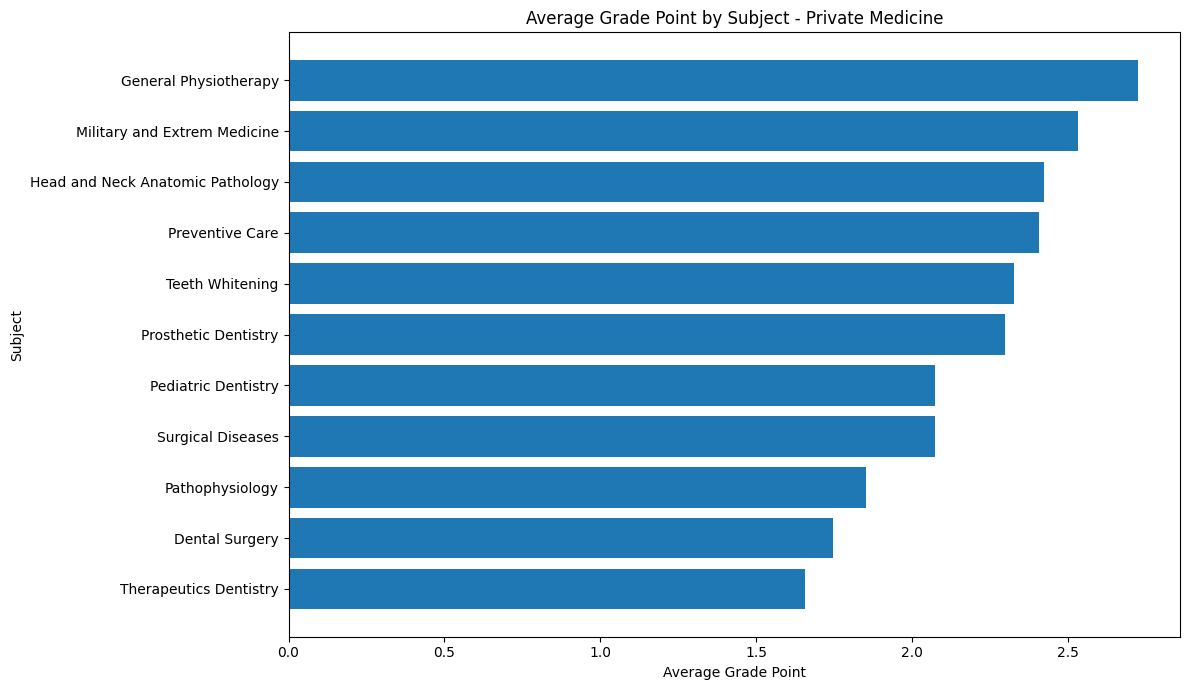

In [23]:
# AVERAGE GRADE POINT BY SUBJECT

subject_avg = (
    subject_analysis_df
    .sort_values(
        "Average Grade Point",
        ascending=True
    )
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    subject_avg["Subject"],
    subject_avg["Average Grade Point"]
)

plt.title("Average Grade Point by Subject - Private Medicine")
plt.xlabel("Average Grade Point")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()

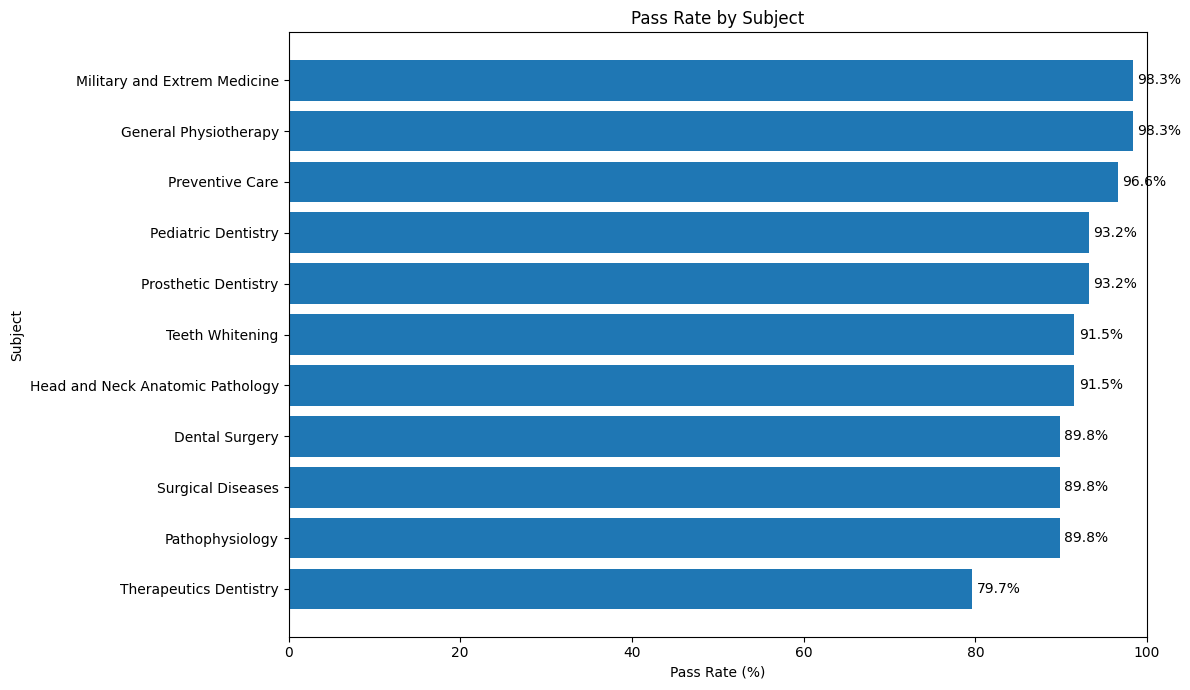

In [24]:
# PASS RATE

pass_rate_df = (
    subject_analysis_df
    .sort_values(
        "Pass Rate %",
        ascending=True
    )
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    pass_rate_df["Subject"],
    pass_rate_df["Pass Rate %"]
)

plt.title("Pass Rate by Subject")
plt.xlabel("Pass Rate (%)")
plt.ylabel("Subject")

plt.xlim(0, 100)

for bar, value in zip(
    bars,
    pass_rate_df["Pass Rate %"]
):
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

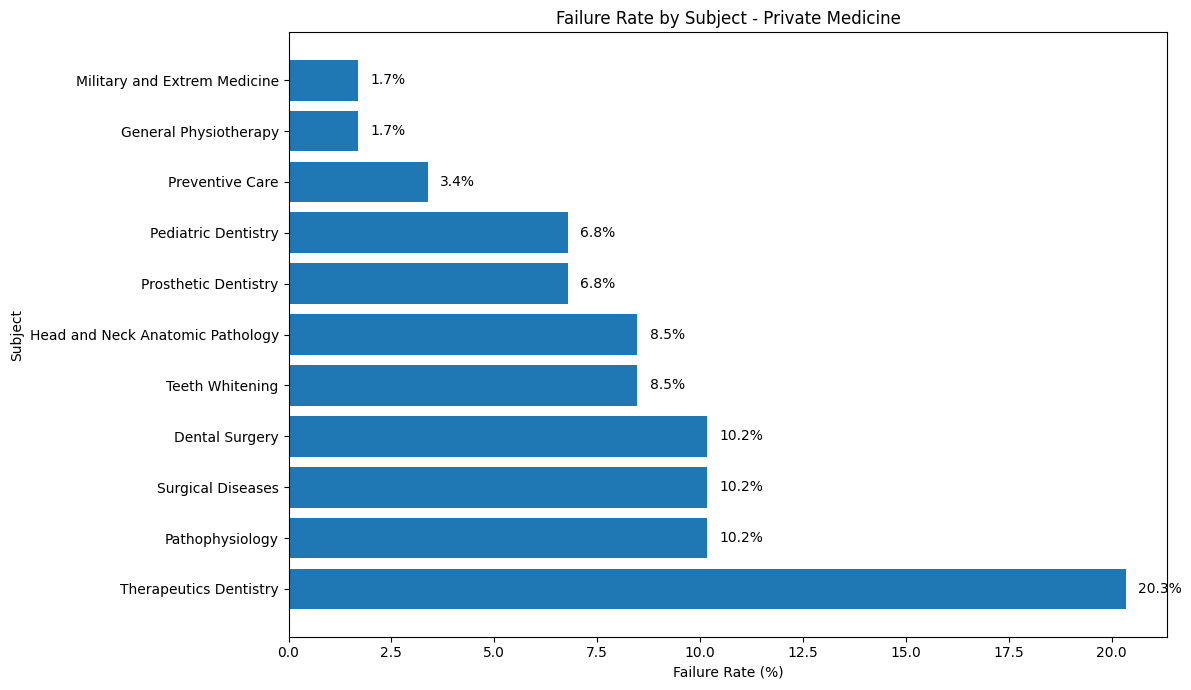

In [25]:
# ============================================================
# FAILURE RATE
# ============================================================

failure_df = (
    subject_analysis_df
    .sort_values(
        "Fail Rate %",
        ascending=False
    )
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    failure_df["Subject"],
    failure_df["Fail Rate %"]
)

plt.title("Failure Rate by Subject - Private Medicine")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Subject")

for bar, value in zip(
    bars,
    failure_df["Fail Rate %"]
):
    plt.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

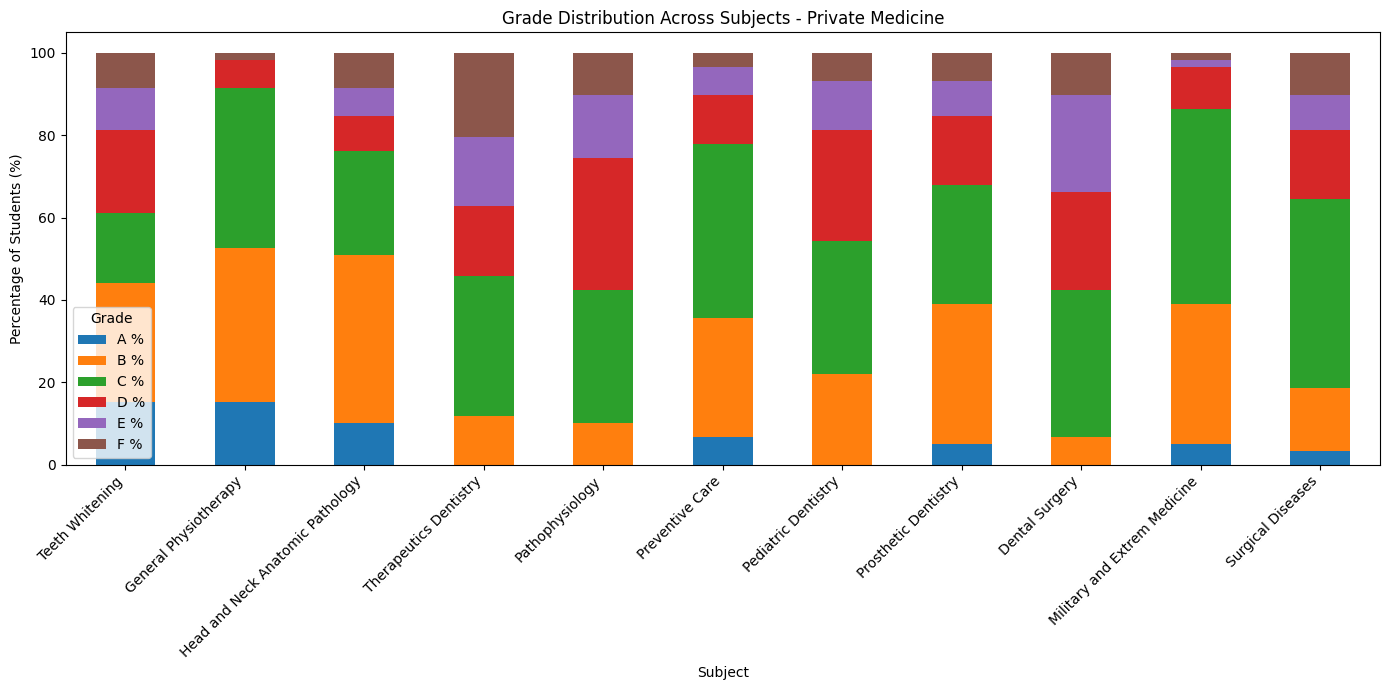

In [26]:
# ============================================================
# GRADE DISTRIBUTION ACROSS SUBJECTS
# ============================================================

grade_distribution_subject = (
    subject_analysis_df[
        [
            "Subject",
            "A %",
            "B %",
            "C %",
            "D %",
            "E %",
            "F %"
        ]
    ]
    .set_index("Subject")
)

ax = grade_distribution_subject.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Grade Distribution Across Subjects - Private Medicine")
plt.xlabel("Subject")
plt.ylabel("Percentage of Students (%)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Grade"
)

plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# NUMBER OF FAILED SUBJECTS
# ============================================================

failed_counts = []

for _, student in final_df.iterrows():

    failed = 0

    for subject in subjects:

        grade = str(
            student[f"{subject} - Grade"]
        ).strip().upper()

        if grade == "F":
            failed += 1

    failed_counts.append(failed)


final_df["Failed Subjects"] = failed_counts

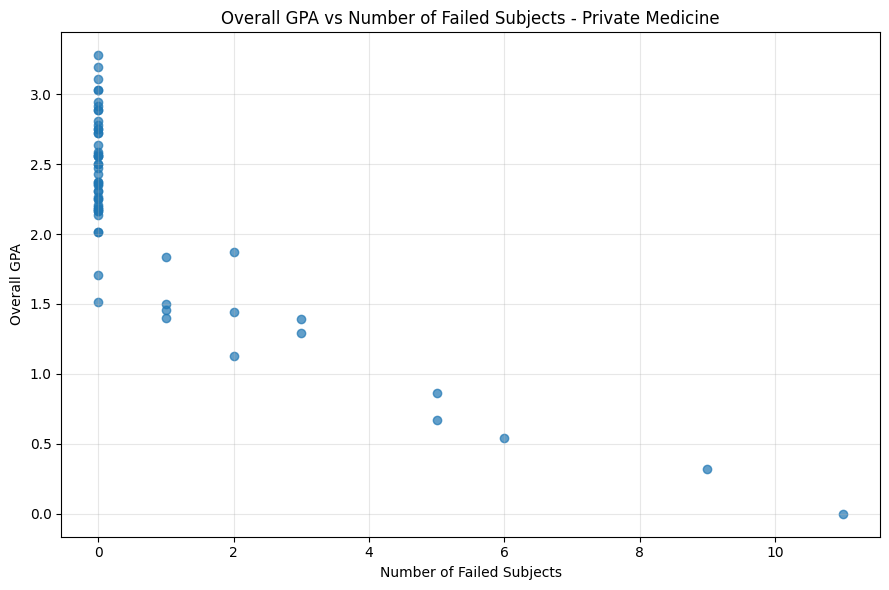

In [28]:
# ============================================================
# GPA VS FAILED SUBJECTS
# ============================================================

plt.figure(figsize=(9, 6))

plt.scatter(
    final_df["Failed Subjects"],
    final_df["Overall GPA"],
    alpha=0.7
)

plt.title("Overall GPA vs Number of Failed Subjects - Private Medicine")
plt.xlabel("Number of Failed Subjects")
plt.ylabel("Overall GPA")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CORRELATION
# ============================================================

correlation = final_df[
    ["Failed Subjects", "Overall GPA"]
].corr()

print(correlation)

                 Failed Subjects  Overall GPA
Failed Subjects         1.000000    -0.826929
Overall GPA            -0.826929     1.000000


In [ ]:
# ============================================================
# STUDENTS WITH ZERO FAILED SUBJECTS
# ============================================================

zero_fail = (
    final_df["Failed Subjects"] == 0
).sum()

one_or_more_fail = (
    final_df["Failed Subjects"] > 0
).sum()

print(f"Students with ZERO F : {zero_fail}")
print(f"Students with >=1 F  : {one_or_more_fail}")

Students with ZERO F : 45
Students with >=1 F  : 14


Failed Subjects
0     45
1      4
2      3
3      2
5      2
6      1
9      1
11     1
Name: count, dtype: int64


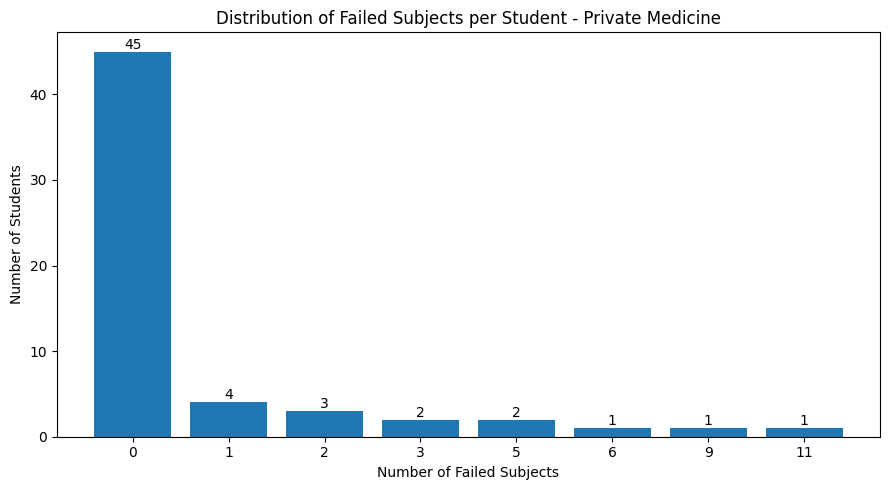

In [29]:
# ============================================================
# FAILED SUBJECTS DISTRIBUTION
# ============================================================

failed_distribution = (
    final_df["Failed Subjects"]
    .value_counts()
    .sort_index()
)

print(failed_distribution)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    failed_distribution.index.astype(str),
    failed_distribution.values
)

plt.title("Distribution of Failed Subjects per Student - Private Medicine")
plt.xlabel("Number of Failed Subjects")
plt.ylabel("Number of Students")

for bar, value in zip(
    bars,
    failed_distribution.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# NUMBER OF A GRADES PER STUDENT
# ============================================================

a_counts = []

for _, student in final_df.iterrows():

    count_a = 0

    for subject in subjects:

        grade = str(
            student[f"{subject} - Grade"]
        ).strip().upper()

        if grade == "A":
            count_a += 1

    a_counts.append(count_a)


final_df["Number of A Grades"] = a_counts


print(
    final_df[
        [
            "Student ID",
            "Number of A Grades",
            "Overall GPA",
            "Overall Grade"
        ]
    ]
    .sort_values(
        "Number of A Grades",
        ascending=False
    )
    .head(10)
)

   Student ID  Number of A Grades  Overall GPA Overall Grade
41     124816                   5        3.194             B
28     124800                   4        2.889             C
12     124779                   4        3.278             B
53     124836                   3        3.028             B
54     124838                   3        3.111             B
9      124773                   3        3.028             B
45     124823                   2        2.916             C
22     124792                   2        2.944             C
13     124780                   1        2.750             C
3      124762                   1        2.569             C


In [31]:
# ============================================================
# FINAL ANALYSIS SUMMARY
# ============================================================

print("=" * 80)
print("FINAL ANALYSIS SUMMARY")
print("=" * 80)

print(f"Students                 : {len(final_df)}")

print(
    f"Average GPA              : "
    f"{final_df['Overall GPA'].mean():.3f}"
)

print(
    f"Highest GPA              : "
    f"{final_df['Overall GPA'].max():.3f}"
)

print(
    f"Lowest GPA               : "
    f"{final_df['Overall GPA'].min():.3f}"
)

print(
    f"Median GPA               : "
    f"{final_df['Overall GPA'].median():.3f}"
)

print(
    f"Students with overall A  : "
    f"{(final_df['Overall Grade'] == 'A').sum()}"
)

print(
    f"Students with overall B  : "
    f"{(final_df['Overall Grade'] == 'B').sum()}"
)

print(
    f"Students with overall C  : "
    f"{(final_df['Overall Grade'] == 'C').sum()}"
)

print(
    f"Students with overall D  : "
    f"{(final_df['Overall Grade'] == 'D').sum()}"
)

print(
    f"Students with overall E  : "
    f"{(final_df['Overall Grade'] == 'E').sum()}"
)

print(
    f"Students with overall F  : "
    f"{(final_df['Overall Grade'] == 'F').sum()}"
)

print()

print(
    f"Students with ZERO F     : "
    f"{(final_df['Failed Subjects'] == 0).sum()}"
)

print(
    f"Students with >=1 F      : "
    f"{(final_df['Failed Subjects'] > 0).sum()}"
)

print()

best_subject = (
    subject_analysis_df
    .loc[
        subject_analysis_df["Average Grade Point"].idxmax(),
        "Subject"
    ]
)

worst_subject = (
    subject_analysis_df
    .loc[
        subject_analysis_df["Average Grade Point"].idxmin(),
        "Subject"
    ]
)

print(
    f"Highest Avg Subject      : {best_subject}"
)

print(
    f"Lowest Avg Subject       : {worst_subject}"
)

print()

most_failed_subject = (
    subject_analysis_df
    .loc[
        subject_analysis_df["Fail Rate %"].idxmax(),
        "Subject"
    ]
)

print(
    f"Most Failed Subject     : "
    f"{most_failed_subject}"
)

print(
    f"Failure Rate             : "
    f"{subject_analysis_df['Fail Rate %'].max():.2f}%"
)

print("=" * 80)

FINAL ANALYSIS SUMMARY
Students                 : 59
Average GPA              : 2.173
Highest GPA              : 3.278
Lowest GPA               : 0.000
Median GPA               : 2.305
Students with overall A  : 0
Students with overall B  : 5
Students with overall C  : 24
Students with overall D  : 14
Students with overall E  : 11
Students with overall F  : 5

Students with ZERO F     : 45
Students with >=1 F      : 14

Highest Avg Subject      : General Physiotherapy
Lowest Avg Subject       : Therapeutics Dentistry

Most Failed Subject     : Therapeutics Dentistry
Failure Rate             : 20.34%
